In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn ucimlrepo jupyter ipykernel

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


### Carregar o Dataset

In [4]:
# Carregar o dataset oficial da UCI
dataset = fetch_ucirepo(id=294)

# Separar as variáveis independentes e a variável dependente
X = dataset.data.features.copy()
y = dataset.data.targets.copy()

# Garantir que a variável alvo seja uma Series
y = y.iloc[:, 0]

# Mostrar as primeiras linhas
display(X.head())

print("Primeiras linhas da variável alvo:")
display(y.head())

,AT,V,AP,RH
0,14.96,41.76,1024.07,73.17
1,25.18,62.96,1020.04,59.08
2,5.11,39.40,1012.16,92.14
3,20.86,57.32,1010.24,76.64
4,10.82,37.50,1009.23,96.62


Primeiras linhas da variável alvo:


0    463.26
1    444.37
2    488.56
3    446.48
4    473.90
Name: PE, dtype: float64

### Informações do dataset

In [5]:
print("Informações gerais:")
X.info()

print("\nResumo estatístico das entradas:")
display(X.describe().T)

print("\nResumo estatístico da variável-alvo PE:")
display(y.describe())

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
dtypes: float64(4)
memory usage: 299.1 KB

Resumo estatístico das entradas:


,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
V,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
AP,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
RH,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16



Resumo estatístico da variável-alvo PE:


count    9568.000000
mean      454.365009
std        17.066995
min       420.260000
25%       439.750000
50%       451.550000
75%       468.430000
max       495.760000
Name: PE, dtype: float64

### Verificação de valores ausentes
precisamos saber se esse dataset possui valores ausentes para saber se é necessario implementar algum tratamento

In [6]:
# Verificar valores ausentes nas variáveis independentes
print("Valores ausentes em X:")
display(X.isnull().sum())

# Verificar valores ausentes na variável dependente
print("\nValores ausentes em PE:", y.isnull().sum())

# Verificar registros duplicados
print("\nQuantidade de linhas duplicadas:", X.join(y.rename("PE")).duplicated().sum())

Valores ausentes em X:


AT    0
V     0
AP    0
RH    0
dtype: int64


Valores ausentes em PE: 0

Quantidade de linhas duplicadas: 41


### Separa dados de treino e teste
vamos separar 80% para o treinamento e 20% para o teste


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Quantidade de amostras para treinamento:", X_train.shape[0])
print("Quantidade de amostras para teste:", X_test.shape[0])

Quantidade de amostras para treinamento: 7654
Quantidade de amostras para teste: 1914


### padronizar as variaveis

In [8]:
# Criar o pipeline
modelo = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("padronizador", StandardScaler()),
    ("regressor", LinearRegression())
])

print("Pipeline criado com sucesso!")

Pipeline criado com sucesso!


### Questão 1: correlação das variaveis independentes e a variavel alvo

In [9]:
# Unir as variáveis independentes e a variável alvo
dados = X.join(y.rename("PE"))

# Calcular a matriz de correlação
matriz_correlacao = dados.corr(numeric_only=True)

# Exibir as correlações das variáveis com PE
correlacoes_pe = matriz_correlacao["PE"].drop("PE")

# Ordenar da maior associação absoluta para a menor
correlacoes_ordenadas = correlacoes_pe.reindex(
    correlacoes_pe.abs().sort_values(ascending=False).index
)

print("Correlação das variáveis independentes com PE:")
display(correlacoes_ordenadas.to_frame(name="Correlação com PE"))

Correlação das variáveis independentes com PE:


,Correlação com PE
AT,-0.948128
V,-0.869780
AP,0.518429
RH,0.389794


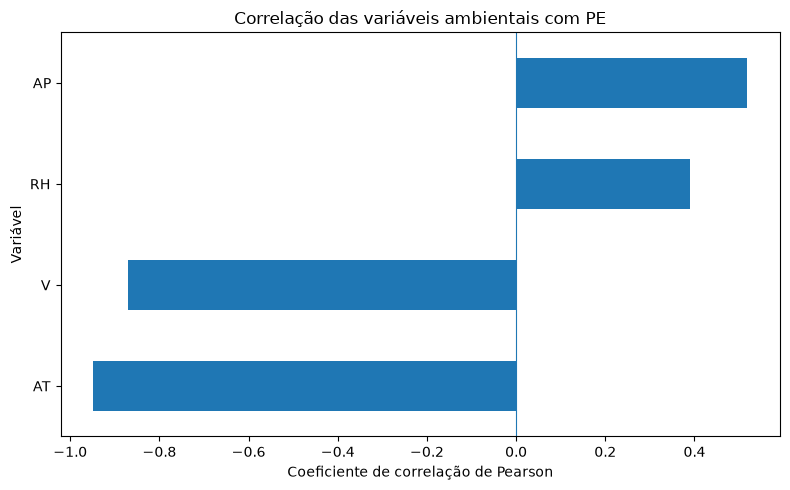

In [10]:
plt.figure(figsize=(8, 5))

correlacoes_ordenadas.sort_values().plot(
    kind="barh"
)

plt.title("Correlação das variáveis ambientais com PE")
plt.xlabel("Coeficiente de correlação de Pearson")
plt.ylabel("Variável")
plt.axvline(0, linewidth=0.8)
plt.tight_layout()
plt.show()

### Questão 2: Correlação entre as variaveis independentes

In [11]:
# Calcular as correlações somente entre as variáveis independentes
correlacao_independentes = X.corr()

display(correlacao_independentes.round(3))

,AT,V,AP,RH
AT,1.000,0.844,-0.508,-0.543
V,0.844,1.000,-0.414,-0.312
AP,-0.508,-0.414,1.000,0.100
RH,-0.543,-0.312,0.100,1.000


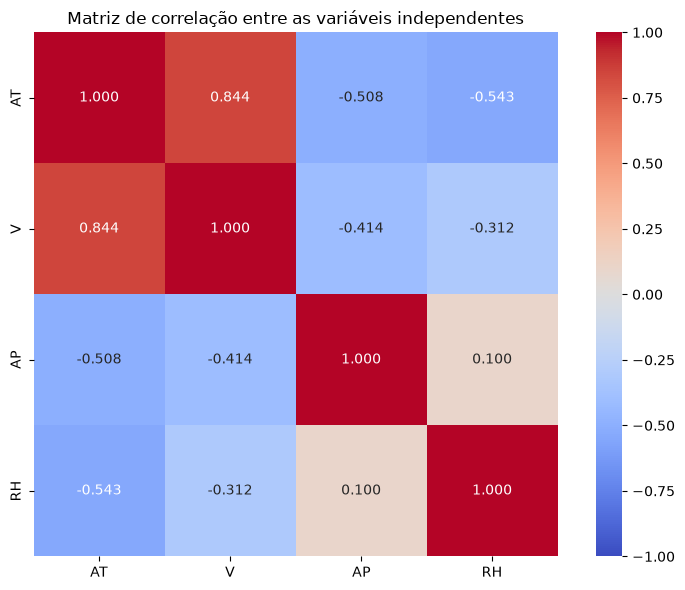

In [12]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacao_independentes,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Matriz de correlação entre as variáveis independentes")
plt.tight_layout()
plt.show()

### Questão 3: Construir o modelo de regressão linear múltipla

In [13]:
# Treinar o modelo com os dados de treinamento
modelo.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [14]:
# Acessar o regressor treinado dentro do pipeline
regressor = modelo.named_steps["regressor"]

# Exibir o intercepto
print("Intercepto:", regressor.intercept_)

# Criar uma tabela com os coeficientes
coeficientes = pd.DataFrame({
    "Variável": X.columns,
    "Coeficiente": regressor.coef_
})

display(coeficientes)

Intercepto: 454.4310399790959


,Variável,Coeficiente
0,AT,-14.763927
1,V,-2.949632
2,AP,0.369780
3,RH,-2.312196


In [15]:
# Prever a produção de energia para os dados de teste
y_pred = modelo.predict(X_test)

# Mostrar algumas previsões
comparacao = pd.DataFrame({
    "PE real (MW)": y_test.values,
    "PE previsto (MW)": y_pred
})

display(comparacao.head(10))

,PE real (MW),PE previsto (MW)
0,455.27,455.680208
1,436.31,438.732122
2,440.68,434.164440
3,434.40,438.769546
4,482.06,479.888329
5,436.07,439.499474
6,452.48,448.840102
7,435.22,434.809190
8,432.93,435.097364
9,466.46,472.947629


In [16]:
# Avaliar o desempenho do modelo
r2 = r2_score(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

mae = mean_absolute_error(y_test, y_pred)

# Exibir os resultados
print("AVALIAÇÃO DO MODELO DE REGRESSÃO LINEAR")
print("-" * 45)

print(f"R²:   {r2:.4f}")
print(f"RMSE: {rmse:.4f} MW")
print(f"MAE:  {mae:.4f} MW")

AVALIAÇÃO DO MODELO DE REGRESSÃO LINEAR
---------------------------------------------
R²:   0.9301
RMSE: 4.5026 MW
MAE:  3.5959 MW


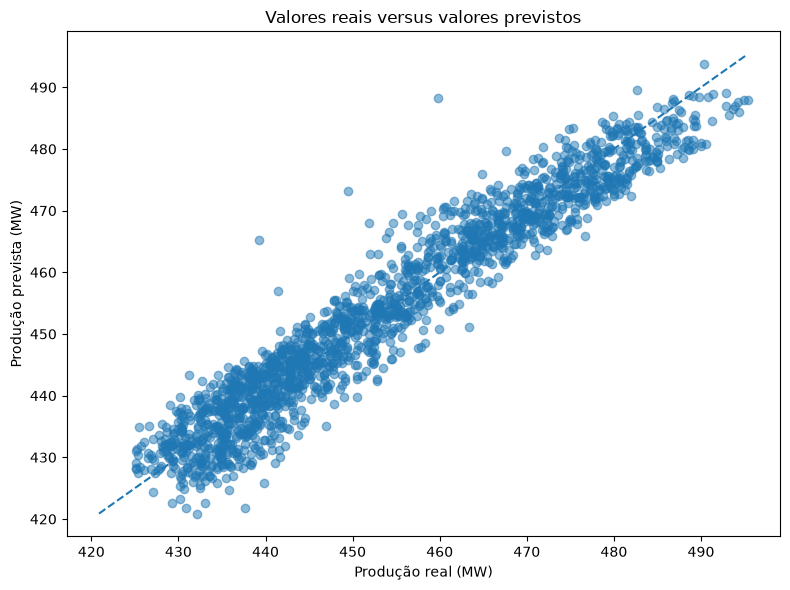

In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

# Linha de previsão perfeita
limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("Produção real (MW)")
plt.ylabel("Produção prevista (MW)")
plt.title("Valores reais versus valores previstos")
plt.tight_layout()
plt.show()